# P2.09 — Wages, unemployment, GDP and the price cycle

**Questions:** RQ9.1 (how have wage growth, unemployment and GDP growth influenced prices?), RQ1.4 (affordability against wage
growth, which `p1_03` covered only through the OECD's income per head). Companion of `p2_08` (mortgage rates).

National annual series, 1995 to 2025: real and nominal house prices (BIS, INE), compensation per employee and GDP growth
(Eurostat national accounts), the unemployment rate (Eurostat labour force survey). Thirty observations and one economy:
co-movements, not causes. Real wages and real prices use the same deflator, so each check is repeated with nominal
values and inflation.

In [1]:
import pandas as pd

from pthousing.analysis import macro
from pthousing.config import PROCESSED
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
long = pd.read_parquet(PROCESSED / "national_annual_long.parquet")
annual = macro.annual_frame(long, interim.read("eurostat_macro"))
print(f"{annual.index.min()}-{annual.index.max()}, {len(annual)} years")

1988-2025, 38 years


## Step 1 — Prices against wages
Compensation per employee deflated with the CPI grew far less than house prices after 2013. The price-to-wage ratio is built
like the price-to-income one (nominal price over nominal earnings) but from national accounts, so it reaches back to 1995 with
a different earnings concept.

,hpi_real_b2015,wage_real_b2015,price_to_wage_b2015,price_to_income_b2015,unemployment_pct
year,,,,,
1995,121.7,90.6,134.4,142.1,7.1
2001,139.4,102.7,135.7,136.2,3.9
2008,115.7,105.7,109.5,107.9,7.7
2013,93.3,101.9,91.5,97.3,16.5
2020,149.3,111.7,133.7,136.6,6.9
2025,213.9,129.9,164.6,166.7,6.0


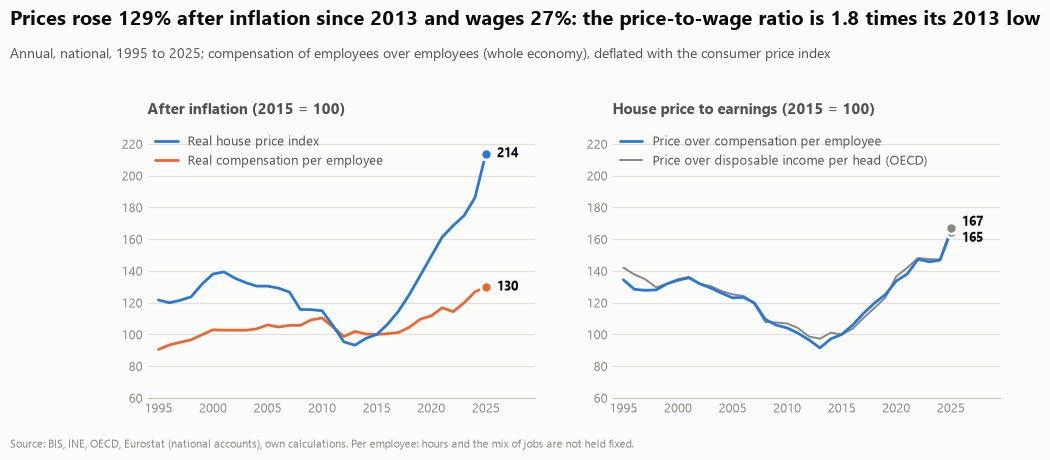

In [2]:
fig = charts.wages_and_prices(annual)
style.save_fig(fig, "p2", "wages_and_prices")
years = [1995, 2001, 2008, 2013, 2020, 2025]
levels = annual.loc[
    years,
    [
        "hpi_real_b2015",
        "wage_real_b2015",
        "price_to_wage_b2015",
        "price_to_income_b2015",
        "unemployment_pct",
    ],
]
style.save_table(levels.round(1).reset_index(), "p2", "wages_prices_levels")
levels.round(1)

## Step 2 — What moves with price growth?
Yearly real price growth on real wage growth, the change in unemployment (pp) and GDP growth. Newey-West errors. Within the
year (`lag 0`) the labour market and prices move together; with the variables one year earlier (`lag 1`) the question becomes
whether they lead. A nominal version (nominal prices on nominal wages, inflation and unemployment) removes the shared deflator.

In [3]:
real = ["wage_growth_real_pct", "unemployment_change_pp", "gdp_growth_pct"]
specs = {
    "lag 0: wages": dict(xs=real[:1]),
    "lag 0: wages, unemployment": dict(xs=real[:2]),
    "lag 0: wages, unemployment, GDP": dict(xs=real),
    "lag 0: ... + last year's growth": dict(xs=real, own_lag=True),
    "lag 0: without 2020-2022": dict(xs=real[:2], drop_years=(2020, 2021, 2022)),
    "lag 1: wages, unemployment, GDP": dict(xs=real, lag=1),
    "lag 1: ... + last year's growth": dict(xs=real, lag=1, own_lag=True),
    "nominal: wages, inflation, unemployment": dict(
        xs=["wage_growth_nominal_pct", "inflation_pct", "unemployment_change_pp"],
        y="price_growth_nominal_pct",
    ),
}
fits = pd.concat(
    {name: macro.fundamentals(annual, **kw) for name, kw in specs.items()},
    names=["specification"],
).reset_index()
style.save_table(fits.round(3), "p2", "price_growth_fundamentals")
fits.round(2)

,specification,term,coef,ci_low,ci_high,p_value,r2,n
0,lag 0: wages,wage_growth_real_pct,1.25,0.76,1.74,0.00,0.35,30
1,"lag 0: wages, unemployment",wage_growth_real_pct,1.00,0.66,1.34,0.00,0.57,30
2,"lag 0: wages, unemployment",unemployment_change_pp,-2.13,-2.74,-1.52,0.00,0.57,30
3,"lag 0: wages, unemployment, GDP",wage_growth_real_pct,1.05,0.63,1.46,0.00,0.58,30
4,"lag 0: wages, unemployment, GDP",unemployment_change_pp,-2.37,-3.14,-1.59,0.00,0.58,30
5,"lag 0: wages, unemployment, GDP",gdp_growth_pct,-0.20,-0.77,0.36,0.48,0.58,30
6,lag 0: ... + last year's growth,wage_growth_real_pct,0.88,0.54,1.22,0.00,0.75,30
7,lag 0: ... + last year's growth,unemployment_change_pp,-1.38,-2.32,-0.44,0.00,0.75,30
8,lag 0: ... + last year's growth,gdp_growth_pct,-0.30,-0.54,-0.05,0.02,0.75,30
9,lag 0: ... + last year's growth,price_growth_lag,0.54,0.34,0.75,0.00,0.75,30


## Step 3 — And rents?
The same regressions with the real growth of the OECD rent index as the outcome. The index covers every lease, old regulated
ones included, so it moves slowly (see `data_quality.md`): it says how the rent of the whole stock of leases follows wages and
unemployment, not what a new tenant pays.

In [4]:
rent_specs = {
    "lag 0: wages": dict(xs=real[:1]),
    "lag 0: wages, unemployment": dict(xs=real[:2]),
    "lag 0: wages, unemployment, GDP": dict(xs=real),
    "lag 1: wages, unemployment": dict(xs=real[:2], lag=1),
}
rent_fits = pd.concat(
    {
        name: macro.fundamentals(annual, y="rent_growth_real_pct", **kw)
        for name, kw in rent_specs.items()
    },
    names=["specification"],
).reset_index()
style.save_table(rent_fits.round(3), "p2", "rent_growth_fundamentals")
rent_fits.round(2)

,specification,term,coef,ci_low,ci_high,p_value,r2,n
0,lag 0: wages,wage_growth_real_pct,0.36,0.11,0.60,0.01,0.24,30
1,"lag 0: wages, unemployment",wage_growth_real_pct,0.34,0.03,0.65,0.03,0.25,30
2,"lag 0: wages, unemployment",unemployment_change_pp,-0.13,-0.79,0.52,0.69,0.25,30
3,"lag 0: wages, unemployment, GDP",wage_growth_real_pct,0.44,0.20,0.67,0.00,0.56,30
4,"lag 0: wages, unemployment, GDP",unemployment_change_pp,-0.64,-1.28,-0.01,0.05,0.56,30
5,"lag 0: wages, unemployment, GDP",gdp_growth_pct,-0.44,-0.70,-0.19,0.00,0.56,30
6,"lag 1: wages, unemployment",wage_growth_real_pct,0.12,-0.13,0.38,0.33,0.03,29
7,"lag 1: wages, unemployment",unemployment_change_pp,-0.05,-0.46,0.36,0.82,0.03,29


## Key numbers

In [5]:
a = annual
low = a["price_to_wage_b2015"].loc[2008:].idxmin()
print(
    f"since {low}: real prices {100 * (a['hpi_real_b2015'].iloc[-1] / a.loc[low, 'hpi_real_b2015'] - 1):+.0f}%, "
    f"real compensation per employee {100 * (a['wage_real_b2015'].iloc[-1] / a.loc[low, 'wage_real_b2015'] - 1):+.0f}%, "
    f"price-to-wage ratio {a['price_to_wage_b2015'].iloc[-1] / a.loc[low, 'price_to_wage_b2015']:.2f}x (2015 = 100: {a['price_to_wage_b2015'].iloc[-1]:.0f}; 1995 {a.loc[1995, 'price_to_wage_b2015']:.0f}, 2001 {a.loc[2001, 'price_to_wage_b2015']:.0f})"
)
for name, grp in fits.groupby("specification", sort=False):
    cells = ", ".join(
        f"{r.term} {r.coef:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]" for r in grp.itertuples()
    )
    print(f"{name} (R2 {grp['r2'].iloc[0]:.2f}, n {grp['n'].iloc[0]}): {cells}")
r = annual
print(
    f"real rents (all leases) since {low}: {100 * (r['rent_real_b2015'].iloc[-1] / r.loc[low, 'rent_real_b2015'] - 1):+.0f}% "
    f"against prices {100 * (a['hpi_real_b2015'].iloc[-1] / a.loc[low, 'hpi_real_b2015'] - 1):+.0f}%"
)
for name, grp in rent_fits.groupby("specification", sort=False):
    cells = ", ".join(
        f"{r_.term} {r_.coef:+.2f} [{r_.ci_low:+.2f}, {r_.ci_high:+.2f}]" for r_ in grp.itertuples()
    )
    print(f"rents, {name} (R2 {grp['r2'].iloc[0]:.2f}, n {grp['n'].iloc[0]}): {cells}")

since 2013: real prices +129%, real compensation per employee +27%, price-to-wage ratio 1.80x (2015 = 100: 165; 1995 134, 2001 136)
lag 0: wages (R2 0.35, n 30): wage_growth_real_pct +1.25 [+0.76, +1.74]
lag 0: wages, unemployment (R2 0.57, n 30): wage_growth_real_pct +1.00 [+0.66, +1.34], unemployment_change_pp -2.13 [-2.74, -1.52]
lag 0: wages, unemployment, GDP (R2 0.58, n 30): wage_growth_real_pct +1.05 [+0.63, +1.46], unemployment_change_pp -2.37 [-3.14, -1.59], gdp_growth_pct -0.20 [-0.77, +0.36]
lag 0: ... + last year's growth (R2 0.75, n 30): wage_growth_real_pct +0.88 [+0.54, +1.22], unemployment_change_pp -1.38 [-2.32, -0.44], gdp_growth_pct -0.30 [-0.54, -0.05], price_growth_lag +0.54 [+0.34, +0.75]
lag 0: without 2020-2022 (R2 0.63, n 27): wage_growth_real_pct +1.03 [+0.65, +1.40], unemployment_change_pp -2.12 [-2.82, -1.43]
lag 1: wages, unemployment, GDP (R2 0.57, n 29): wage_growth_real_pct +1.02 [+0.50, +1.53], unemployment_change_pp -2.73 [-3.96, -1.49], gdp_growth_pct